# Promise Status Baseline: Parquet Embeddings + Classifier

這份 notebook 直接讀取已經產好的 embedding parquet，聚焦比較不同 classifier 在 `promise_status` 上的表現。

目前不再呼叫 embedding API，也不再即時產生 embedding。

In [70]:
import json
import pathlib
import warnings

import joblib
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np
import pandas as pd
import plotly.express as px
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import NearestNeighbors
from xgboost import XGBClassifier
import umap

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 200)

SEED = 42
N_SPLITS = 5
is_richard = False
richard_dir = "/mnt/share_data_79/embedd_ft_result/embeddings_mixed_ft/"

our_dir = "exp/exp1/results/baseline/"
our_dir = "exp/exp1/results/qwen-embedding-4b-ft"
our_dir = "results/qwen-embedding-8b-richard"
EMBEDDINGS_DIR = pathlib.Path(richard_dir) if is_richard else pathlib.Path(our_dir) 
MANIFEST_PATH = EMBEDDINGS_DIR / "manifest.json"


print(EMBEDDINGS_DIR)
print(MANIFEST_PATH)

results/qwen-embedding-8b-richard
results/qwen-embedding-8b-richard/manifest.json


In [71]:
with MANIFEST_PATH.open("r", encoding="utf-8") as f:
    manifest = json.load(f)

if is_richard:
    base_dir = "/mnt/share_data_79/embedd_ft_result/embeddings_mixed_ft/"
    manifest = [{**c, "output_path": base_dir + c["output_path"].split("/")[-1]} for c in manifest]
manifest_df = pd.DataFrame(manifest)
manifest_df

,model_name,rows,embedding_dim,output_path
0,qwen-embedding-8b,1000,4096,/tmp2/howard/side_project/ESG_AIDEA/finetune/results/qwen-embedding-8b-richard/baseline.parquet


In [72]:
def load_embedding_frame(parquet_path: str) -> pd.DataFrame:
    """Loads one parquet file and normalizes labels."""
    frame = pd.read_parquet(parquet_path)
    frame["label"] = (frame["promise_status"] == "Yes").astype(int)
    return frame


sample_frame = load_embedding_frame(manifest_df.iloc[0]["output_path"])
print(sample_frame.columns.tolist())
sample_frame[["record_id", "model_name", "promise_status", "embedding_dim"]].head()

['record_id', 'model_name', 'text', 'text_sha1', 'embedding_dim', 'embedding', 'promise_status', 'promise_string', 'verification_timeline', 'evidence_status', 'evidence_quality', 'esg_type', 'company', 'ticker', 'page_number', 'label']


,record_id,model_name,promise_status,embedding_dim
0,10001,qwen-embedding-8b,Yes,4096
1,10002,qwen-embedding-8b,Yes,4096
2,10003,qwen-embedding-8b,Yes,4096
3,10004,qwen-embedding-8b,Yes,4096
4,10005,qwen-embedding-8b,Yes,4096


In [73]:
sample_frame[:1]

,record_id,model_name,text,text_sha1,embedding_dim,embedding,promise_status,promise_string,verification_timeline,evidence_status,evidence_quality,esg_type,company,ticker,page_number,label
0,10001,qwen-embedding-8b,聯發科技除在「工作規則」中依照勞基法明確規定「員工在產假期間公司不得終止勞動契約」外，為支持同仁與其家人度過人生不同階段，自 2024 年起提供女性員工在分娩前後計有 12 週共 84 天的產假；男性員工則可於其配偶懷孕期間陪同產檢或生（流）產日及前後 15 日間請假陪伴，兩者合計共有 10 天陪產（檢）假可運用，陪產（檢）假期間工資照常給付。,4b80bc9ef7dadf28b7728d0003699aa0866ff235,4096,"[-0.0120849609375, -0.01190948486328125, -0.00344085693359375, 0.0158538818359375, 0.0223388671875, 0.00424957275390625, 0.0131378173828125, 0.01171875, 0.0008611679077148438, -0.035003662109375, ...",Yes,為支持同仁與其家人度過人生不同階段，自 2024 年起提供女性員工在分娩前後計有 12 週共 84 天的產假；男性員工則可於其配偶懷孕期間陪同產檢或生（流）產日及前後 15 日間請假陪伴，兩者合計共有 10 天陪產（檢）假可運用，陪產（檢）假期間工資照常給付。,already,No,,S,mediatek,2454,48,1


In [74]:
def build_xy(frame: pd.DataFrame) -> tuple[np.ndarray, np.ndarray]:
    """Builds numpy matrices from the parquet structure."""
    features = np.asarray(frame["embedding"].tolist(), dtype=np.float32)
    labels = frame["label"].to_numpy(dtype=np.int64)
    return features, labels


X_sample, y_sample = build_xy(sample_frame)
print("sample X shape:", X_sample.shape)
print("sample positive ratio:", y_sample.mean())

sample X shape: (1000, 4096)
sample positive ratio: 0.814


## Embedding Distribution Preview

先不跑 classifier，直接把讀進來的 embedding 做 UMAP 降到 2D / 3D，觀察 `promise_status` 的資料分布。

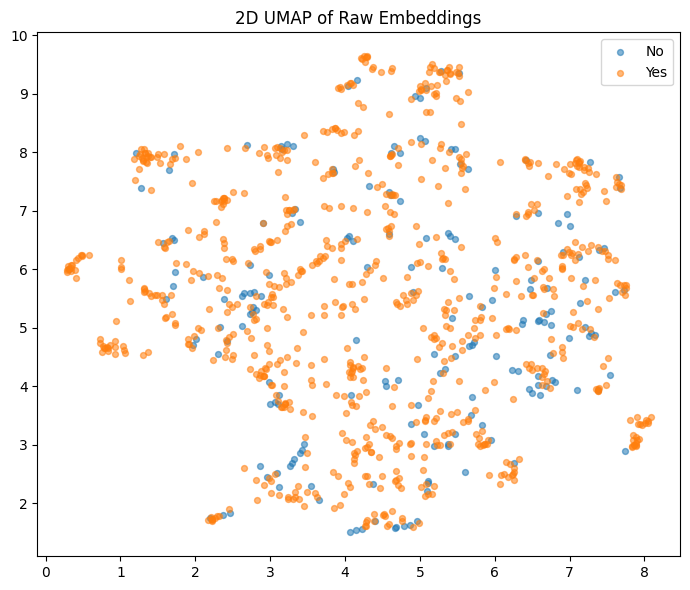

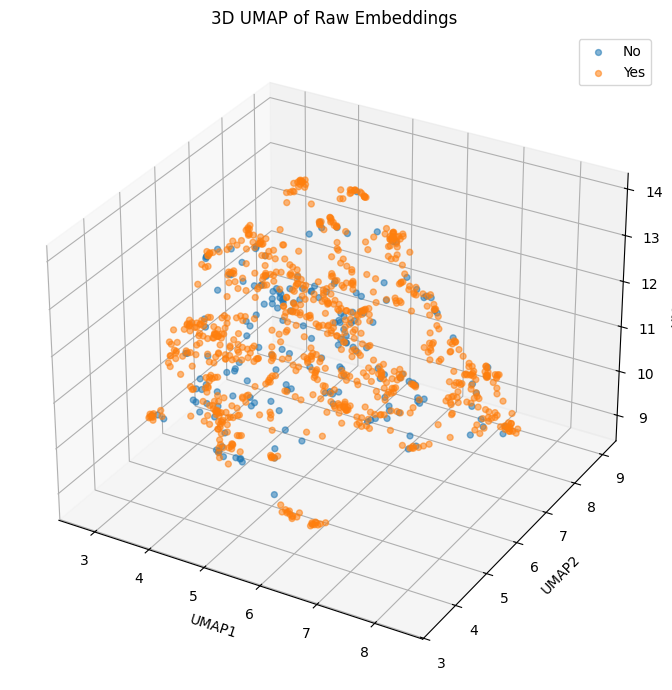

In [75]:
# 一讀進 embedding 就先看資料分布
preview_frame = sample_frame.copy()
preview_max_points = 2000
if len(preview_frame) > preview_max_points:
    preview_frame = preview_frame.sample(
        preview_max_points,
        random_state=SEED,
    ).copy()

preview_X, preview_y = build_xy(preview_frame)

preview_umap_2d = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="cosine",
    random_state=SEED,
)
preview_2d = preview_umap_2d.fit_transform(preview_X)

plt.figure(figsize=(7, 6))
plt.scatter(
    preview_2d[preview_y == 0, 0],
    preview_2d[preview_y == 0, 1],
    s=18,
    alpha=0.55,
    label="No",
)
plt.scatter(
    preview_2d[preview_y == 1, 0],
    preview_2d[preview_y == 1, 1],
    s=18,
    alpha=0.55,
    label="Yes",
)
plt.title("2D UMAP of Raw Embeddings")
plt.legend()
plt.tight_layout()
plt.show()

preview_umap_3d = umap.UMAP(
    n_components=3,
    n_neighbors=15,
    min_dist=0.1,
    metric="cosine",
    random_state=SEED,
)
preview_3d = preview_umap_3d.fit_transform(preview_X)

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(
    preview_3d[preview_y == 0, 0],
    preview_3d[preview_y == 0, 1],
    preview_3d[preview_y == 0, 2],
    s=18,
    alpha=0.55,
    label="No",
)
ax.scatter(
    preview_3d[preview_y == 1, 0],
    preview_3d[preview_y == 1, 1],
    preview_3d[preview_y == 1, 2],
    s=18,
    alpha=0.55,
    label="Yes",
)
ax.set_title("3D UMAP of Raw Embeddings")
ax.set_xlabel("UMAP1")
ax.set_ylabel("UMAP2")
ax.set_zlabel("UMAP3")
ax.legend()
plt.tight_layout()
plt.show()


## LLM Prediction Distribution

把語言模型的預測結果和 embedding 對齊，分別觀察預測正確與預測錯誤樣本在 UMAP 空間中的分布。

In [76]:
'''
with LLM_PREDICTIONS_PATH.open("r", encoding="utf-8") as f:
    llm_predictions = json.load(f)

llm_predictions_df = pd.DataFrame(llm_predictions)
llm_predictions_df["record_id"] = llm_predictions_df["id"].astype(str)
sample_frame["record_id"] = sample_frame["record_id"].astype(str)

llm_viz_df = sample_frame.merge(
    llm_predictions_df[["record_id", "gold", "prediction"]],
    on="record_id",
    how="inner",
).copy()
llm_viz_df["is_correct"] = llm_viz_df["gold"] == llm_viz_df["prediction"]
llm_viz_df["match_type"] = np.where(
    llm_viz_df["is_correct"],
    "Correct",
    "Wrong",
)

llm_viz_X, _ = build_xy(llm_viz_df)
llm_umap_2d = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="cosine",
    random_state=SEED,
)
llm_viz_2d = llm_umap_2d.fit_transform(llm_viz_X)
llm_viz_df[["umap_x", "umap_y"]] = llm_viz_2d
llm_umap_3d = umap.UMAP(
    n_components=3,
    n_neighbors=15,
    min_dist=0.1,
    metric="cosine",
    random_state=SEED,
)
llm_viz_3d = llm_umap_3d.fit_transform(llm_viz_X)
llm_viz_df[["umap_x_3d", "umap_y_3d", "umap_z_3d"]] = llm_viz_3d

correct_viz_df = llm_viz_df[llm_viz_df["is_correct"]].copy()
wrong_viz_df = llm_viz_df[~llm_viz_df["is_correct"]].copy()

print("correct count:", len(correct_viz_df))
print("wrong count:", len(wrong_viz_df))
print("UMAP params: n_neighbors=15, min_dist=0.1, metric=cosine")

plt.figure(figsize=(7, 6))
plt.scatter(
    correct_viz_df.loc[correct_viz_df["gold"] == "No", "umap_x"],
    correct_viz_df.loc[correct_viz_df["gold"] == "No", "umap_y"],
    s=18,
    alpha=0.6,
    label="Gold No",
)
plt.scatter(
    correct_viz_df.loc[correct_viz_df["gold"] == "Yes", "umap_x"],
    correct_viz_df.loc[correct_viz_df["gold"] == "Yes", "umap_y"],
    s=18,
    alpha=0.6,
    label="Gold Yes",
)
plt.title("LLM Correct Predictions in 2D UMAP Space")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 6))
plt.scatter(
    wrong_viz_df.loc[wrong_viz_df["gold"] == "No", "umap_x"],
    wrong_viz_df.loc[wrong_viz_df["gold"] == "No", "umap_y"],
    s=22,
    alpha=0.75,
    label="Gold No",
)
plt.scatter(
    wrong_viz_df.loc[wrong_viz_df["gold"] == "Yes", "umap_x"],
    wrong_viz_df.loc[wrong_viz_df["gold"] == "Yes", "umap_y"],
    s=22,
    alpha=0.75,
    label="Gold Yes",
)
plt.title("LLM Wrong Predictions in 2D UMAP Space")
plt.legend()
plt.tight_layout()
plt.show()

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(
    correct_viz_df.loc[correct_viz_df["gold"] == "No", "umap_x_3d"],
    correct_viz_df.loc[correct_viz_df["gold"] == "No", "umap_y_3d"],
    correct_viz_df.loc[correct_viz_df["gold"] == "No", "umap_z_3d"],
    s=18,
    alpha=0.6,
    label="Gold No",
)
ax.scatter(
    correct_viz_df.loc[correct_viz_df["gold"] == "Yes", "umap_x_3d"],
    correct_viz_df.loc[correct_viz_df["gold"] == "Yes", "umap_y_3d"],
    correct_viz_df.loc[correct_viz_df["gold"] == "Yes", "umap_z_3d"],
    s=18,
    alpha=0.6,
    label="Gold Yes",
)
ax.set_title("LLM Correct Predictions in 3D UMAP Space")
ax.set_xlabel("UMAP1")
ax.set_ylabel("UMAP2")
ax.set_zlabel("UMAP3")
ax.legend()
plt.tight_layout()
plt.show()

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(
    wrong_viz_df.loc[wrong_viz_df["gold"] == "No", "umap_x_3d"],
    wrong_viz_df.loc[wrong_viz_df["gold"] == "No", "umap_y_3d"],
    wrong_viz_df.loc[wrong_viz_df["gold"] == "No", "umap_z_3d"],
    s=24,
    alpha=0.75,
    label="Gold No",
)
ax.scatter(
    wrong_viz_df.loc[wrong_viz_df["gold"] == "Yes", "umap_x_3d"],
    wrong_viz_df.loc[wrong_viz_df["gold"] == "Yes", "umap_y_3d"],
    wrong_viz_df.loc[wrong_viz_df["gold"] == "Yes", "umap_z_3d"],
    s=24,
    alpha=0.75,
    label="Gold Yes",
)
ax.set_title("LLM Wrong Predictions in 3D UMAP Space")
ax.set_xlabel("UMAP1")
ax.set_ylabel("UMAP2")
ax.set_zlabel("UMAP3")
ax.legend()
plt.tight_layout()
plt.show()

interactive_columns = [
    "record_id",
    "gold",
    "prediction",
    "match_type",
    "text",
]

fig = px.scatter_3d(
    correct_viz_df,
    x="umap_x_3d",
    y="umap_y_3d",
    z="umap_z_3d",
    color="gold",
    hover_data=interactive_columns,
    title="Interactive LLM Correct Predictions in 3D UMAP Space",
    opacity=0.7,
)
fig.update_traces(marker={"size": 4})
fig.show()

fig = px.scatter_3d(
    wrong_viz_df,
    x="umap_x_3d",
    y="umap_y_3d",
    z="umap_z_3d",
    color="gold",
    hover_data=interactive_columns,
    title="Interactive LLM Wrong Predictions in 3D UMAP Space",
    opacity=0.75,
)
fig.update_traces(marker={"size": 5})
fig.show()
'''


'\nwith LLM_PREDICTIONS_PATH.open("r", encoding="utf-8") as f:\n    llm_predictions = json.load(f)\n\nllm_predictions_df = pd.DataFrame(llm_predictions)\nllm_predictions_df["record_id"] = llm_predictions_df["id"].astype(str)\nsample_frame["record_id"] = sample_frame["record_id"].astype(str)\n\nllm_viz_df = sample_frame.merge(\n    llm_predictions_df[["record_id", "gold", "prediction"]],\n    on="record_id",\n    how="inner",\n).copy()\nllm_viz_df["is_correct"] = llm_viz_df["gold"] == llm_viz_df["prediction"]\nllm_viz_df["match_type"] = np.where(\n    llm_viz_df["is_correct"],\n    "Correct",\n    "Wrong",\n)\n\nllm_viz_X, _ = build_xy(llm_viz_df)\nllm_umap_2d = umap.UMAP(\n    n_components=2,\n    n_neighbors=15,\n    min_dist=0.1,\n    metric="cosine",\n    random_state=SEED,\n)\nllm_viz_2d = llm_umap_2d.fit_transform(llm_viz_X)\nllm_viz_df[["umap_x", "umap_y"]] = llm_viz_2d\nllm_umap_3d = umap.UMAP(\n    n_components=3,\n    n_neighbors=15,\n    min_dist=0.1,\n    metric="cosine",\n 

In [77]:
models = {
    "logreg": LogisticRegression(
        random_state=SEED,
        max_iter=2000,
        class_weight="balanced",
    ),
    "xgboost": XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=SEED,
        n_jobs=4,
    ),
}

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

In [78]:
summary_rows = []
oof_predictions = {}
oof_probabilities = {}
frames_by_model = {}

for row in manifest:
    model_name = row["model_name"]
    frame = load_embedding_frame(row["output_path"])
    frames_by_model[model_name] = frame
    X, y = build_xy(frame)

    for classifier_name, classifier in models.items():
        binary_scores = []
        macro_scores = []
        weighted_scores = []
        oof_pred = np.zeros_like(y)
        oof_proba = np.zeros(len(y), dtype=np.float32)

        for fold_id, (train_idx, valid_idx) in enumerate(skf.split(X, y), start=1):
            X_train, X_valid = X[train_idx], X[valid_idx]
            y_train, y_valid = y[train_idx], y[valid_idx]
            # sample_weight = np.where(y_train == 0, 4.0, 1.0)
            fold_model = clone(classifier)
            fold_model.fit(
                X_train,
                y_train,
                # sample_weight=sample_weight,
            )
            valid_pred = fold_model.predict(X_valid)
            valid_proba = fold_model.predict_proba(X_valid)[:, 1]
            oof_pred[valid_idx] = valid_pred
            oof_proba[valid_idx] = valid_proba.astype(np.float32)

            binary_f1 = f1_score(y_valid, valid_pred, average="binary")
            macro_f1 = f1_score(y_valid, valid_pred, average="macro")
            weighted_f1 = f1_score(y_valid, valid_pred, average="weighted")
            binary_scores.append(binary_f1)
            macro_scores.append(macro_f1)
            weighted_scores.append(weighted_f1)
            print(
                f"{model_name} | {classifier_name} | fold {fold_id}: "
                f"binary={binary_f1:.4f} macro={macro_f1:.4f} "
                f"weighted={weighted_f1:.4f}"
            )

        key = (model_name, classifier_name)
        oof_predictions[key] = oof_pred
        oof_probabilities[key] = oof_proba
        summary_rows.append(
            {
                "embedding_model": model_name,
                "classifier": classifier_name,
                "cv_binary_f1_mean": float(np.mean(binary_scores)),
                "cv_binary_f1_std": float(np.std(binary_scores)),
                "cv_macro_f1_mean": float(np.mean(macro_scores)),
                "cv_macro_f1_std": float(np.std(macro_scores)),
                "cv_weighted_f1_mean": float(np.mean(weighted_scores)),
                "cv_weighted_f1_std": float(np.std(weighted_scores)),
                "rows": int(len(frame)),
                "embedding_dim": int(X.shape[1]),
            }
        )

results_df = pd.DataFrame(summary_rows).sort_values(
    ["cv_macro_f1_mean", "cv_weighted_f1_mean", "cv_macro_f1_std"],
    ascending=[False, False, True],
)
results_df

qwen-embedding-8b | logreg | fold 1: binary=0.8255 macro=0.6578 weighted=0.7635
qwen-embedding-8b | logreg | fold 2: binary=0.8283 macro=0.6666 weighted=0.7684
qwen-embedding-8b | logreg | fold 3: binary=0.8846 macro=0.7378 weighted=0.8303
qwen-embedding-8b | logreg | fold 4: binary=0.8824 macro=0.7497 weighted=0.8333
qwen-embedding-8b | logreg | fold 5: binary=0.8673 macro=0.7084 weighted=0.8069
qwen-embedding-8b | xgboost | fold 1: binary=0.9106 macro=0.5744 weighted=0.7862
qwen-embedding-8b | xgboost | fold 2: binary=0.9056 macro=0.5278 weighted=0.7658
qwen-embedding-8b | xgboost | fold 3: binary=0.9101 macro=0.5914 weighted=0.7922
qwen-embedding-8b | xgboost | fold 4: binary=0.9122 macro=0.6263 weighted=0.8064
qwen-embedding-8b | xgboost | fold 5: binary=0.8994 macro=0.5211 weighted=0.7557


,embedding_model,classifier,cv_binary_f1_mean,cv_binary_f1_std,cv_macro_f1_mean,cv_macro_f1_std,cv_weighted_f1_mean,cv_weighted_f1_std,rows,embedding_dim
0,qwen-embedding-8b,logreg,0.857614,0.025794,0.704050,0.036817,0.800477,0.029665,1000,4096
1,qwen-embedding-8b,xgboost,0.907581,0.004629,0.568201,0.039499,0.781254,0.018275,1000,4096


In [80]:
best_row = results_df.iloc[0]
best_embedding_model = best_row["embedding_model"]
best_classifier_name = best_row["classifier"]
best_frame = frames_by_model[best_embedding_model]
best_y = best_frame["label"].to_numpy(dtype=np.int64)
best_pred = oof_predictions[(best_embedding_model, best_classifier_name)]
best_proba = oof_probabilities[(best_embedding_model, best_classifier_name)]

print("best embedding model:", best_embedding_model)
print("best classifier:", best_classifier_name)
print(
    "selected by macro F1:",
    f"{best_row['cv_macro_f1_mean']:.4f} +/- {best_row['cv_macro_f1_std']:.4f}"
)
print(
    "binary F1:",
    f"{best_row['cv_binary_f1_mean']:.4f} +/- {best_row['cv_binary_f1_std']:.4f}"
)
print(
    "weighted F1:",
    f"{best_row['cv_weighted_f1_mean']:.4f} +/- {best_row['cv_weighted_f1_std']:.4f}"
)
print(classification_report(best_y, best_pred, target_names=["No", "Yes"]))
print("confusion matrix:")
print(confusion_matrix(best_y, best_pred))

best embedding model: qwen-embedding-8b
best classifier: logreg
selected by macro F1: 0.7040 +/- 0.0368
binary F1: 0.8576 +/- 0.0258
weighted F1: 0.8005 +/- 0.0297
              precision    recall  f1-score   support

          No       0.45      0.70      0.55       186
         Yes       0.92      0.80      0.86       814

    accuracy                           0.78      1000
   macro avg       0.69      0.75      0.70      1000
weighted avg       0.83      0.78      0.80      1000

confusion matrix:
[[131  55]
 [161 653]]
